# E7 Estimated TPOT

仅包含 TPOT 对比图。数据由 `build_e7_figures.ipynb` 的分项耗时求和提取，以显式数组放在绘图单元格顶部，单位为 ms；这是 estimated TPOT。样式、函数结构和 PDF 保存方式与 `kernel_Speedup.ipynb` 对齐。运行下面两个代码单元格即可预览并保存 `tpot_perf.pdf`。

In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pad_inches": 0.1}
import csv
import json
from pathlib import Path
from matplotlib.legend_handler import HandlerPatch
from matplotlib.patches import Rectangle

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
from IPython.display import display

TEAL, BLUE, ORANGE, GRAY, INK = "#008b87", "#4f7192", "#c76524", "#737b81", "#243136"

def setup_style():
    plt.rcParams["hatch.linewidth"] = 0.5
    for name in ("Times New Roman.ttf", "Times New Roman Bold.ttf", "Times New Roman Italic.ttf"):
        path = Path("/System/Library/Fonts/Supplemental") / name
        if path.exists():
            font_manager.fontManager.addfont(str(path))
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"], "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.linewidth": .6, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK, "savefig.facecolor": "white"})

def axis_style(ax, grid_axis="both"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(width=.6, length=2, pad=2)
    ax.grid(axis=grid_axis, color="#dce2e5", linewidth=.45, zorder=0)
    ax.set_axisbelow(True)

setup_style()

## Selection frontend excluded：绘图数据与对比图

数据源：`thoughts/补充实验/e7_estimated_tpot/e7_v1_simplified_projection/E7_v1_attention_only.csv`。

这是**不含选择前端的组件估算**：包含32层公共计算、两个FlashInfer dense attention层、30个稀疏attention层和输出投影；排除selection、estimator、refinement、union和metadata，不是完整端到端TPOT。Quest为E6 profile-sized per-head adapter。32K/B128缺数据，保留N/A。

下表时延单位为 **ms**。为与前一个代码块一致，**柱顶使用FA2 / 当前方法**；另列GAS相对FlashInfer的加速比，便于核对。表格保留三位小数，绘图数组保留源数据精度。

| Context | Batch | FA2 | FlashInfer | Quest | Twilight | GAS | Less-style 8% |
|---|---:|---:|---:|---:|---:|---:|---:|
| 16K | 32 | 51.872 | 42.607 | 22.775 | 20.624 | 18.552 | 20.657 |
| 16K | 64 | 74.810 | 58.931 | 30.827 | 25.403 | 22.842 | 27.189 |
| 16K | 96 | 107.772 | 78.385 | 37.961 | 29.246 | 26.173 | 32.861 |
| 16K | 128 | 132.532 | 96.003 | 44.372 | 32.219 | 28.545 | 37.580 |
| 32K* | 32 | 87.657 | 67.555 | 30.971 | 23.685 | 21.159 | 26.286 |
| 32K* | 64 | 136.332 | 101.515 | 47.604 | 33.963 | 29.991 | 40.080 |
| 32K* | 96 | 199.371 | 138.953 | 58.919 | 38.528 | 33.633 | 47.609 |
| 32K* | 128 | 252.666 | 174.151 | 73.800 | 45.649 | 39.42 | 57.981 |

先运行上方样式初始化单元格（含 `setup_style` 和 `axis_style`），再运行下面新增的绘图单元格。无需重新运行旧版数据绘图；导出为同目录 `tpot_frontend_excluded.pdf`，保留原图。


Saved: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig7-TPOT result/NewEnv/tpot_frontend_excluded.pdf


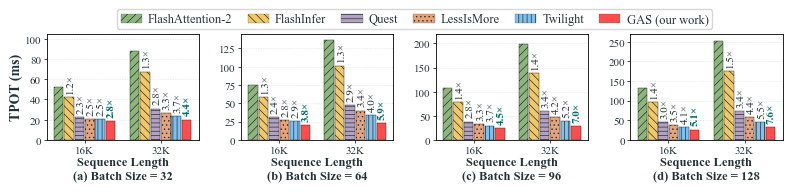

In [6]:
# New data: selection-frontend-excluded projection (ms), 2026-10-23.
# Rows: B32, B64, B96, B128; columns: 16K, 32K.
# Includes common/output costs; excludes selection/estimation/refinement/metadata.
# Sparse layers: 2 FlashInfer dense + 30 sparse. Bar labels: FA2 / method.
TPOT_EXCLUDED_BATCHES = (32, 64, 96, 128)
TPOT_EXCLUDED_LENGTHS = (16384, 32768)
TPOT_EXCLUDED_MS = {
    "fa2": np.array([
    [51.872, 87.657],  # B32
    [74.810, 136.332],  # B64
    [107.772, 199.371],  # B96
    [132.532, 252.666],  # B128
]),
"flashinfer": np.array([
    [42.607, 67.555],  # B32
    [58.931, 101.515],  # B64
    [78.385, 138.953],  # B96
    [96.003, 174.151],  # B128
]),
"quest": np.array([
    [22.775, 30.971],  # B32
    [30.827, 47.604],  # B64
    [37.961, 58.919],  # B96
    [44.372, 73.800],  # B128
]),

"lessismore": np.array([
    [20.657, 26.286],    # B32
    [27.189, 40.080],     # B64
    [32.861, 47.609],   # B96
    [37.580, 57.981],   # B128
]),

"quest_twi": np.array([
    [20.624, 23.685],  # B32
    [25.403, 33.963],  # B64
    [29.246, 38.528],  # B96
    [32.219, 45.649],  # B128
]),
# original- FI
# "gas": np.array([
#     [18.552, 21.159],  # B32
#     [22.842, 29.991],  # B64
#     [26.173, 33.633],  # B96
#     [28.545, 39.42],  # B128
# ]),

#  fused kernel
"gas": np.array([
    [18.406, 20.141],  # B32:  16K, 32K
    [19.645, 23.022],  # B64
    [23.877, 28.326],  # B96
    [25.939, 33.322],  # B128
]),
    
}

# TPOT_EXCLUDED_STYLES = [
#     ("fa2", "FlashAttention-2", "#8DB67A", "///"),
#     ("flashinfer", "FlashInfer", "#F2C867", '\\\\\\'),
#     ("quest", "Quest", "#B5A0C2", "||||"),
#     ("lessismore", "LessIsMore", "#E7A47C", "+++"),
#     ("quest_twi", "Twilight", "#7EC0EE", "----"),
#     ("gas", "GAS (our work)", "#FF4D4D", ""),
# ]

TPOT_EXCLUDED_STYLES = [
    ('fa2', 'FlashAttention-2', '#8DB67A', '////'),
    ('flashinfer', 'FlashInfer', '#F2C867', '\\\\\\\\'),
    ('quest', 'Quest', '#B5A0C2', '----'),
    ('lessismore', 'LessIsMore', '#E7A47C', '....'),
    ('quest_twi', 'Twilight', '#7EC0EE', '||||'),
    ('gas', 'GAS (our work)', '#FF4D4D', ''),
]

class LoweredLegendPatch(HandlerPatch):
    """Lower legend color swatches slightly to align visually with the text."""
    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        artists = super().create_artists(legend, orig_handle, xdescent, ydescent,
                                         width, height, fontsize, trans)
        for artist in artists:
            artist.set_y(artist.get_y() - 0.8)  # points; increase to lower further
        return artists

def tpot_excluded_figure(latency_ms, batches=TPOT_EXCLUDED_BATCHES, lengths=TPOT_EXCLUDED_LENGTHS, styles=None):
    """Return an editable full-width figure; frontend-excluded projection axes start at zero."""
    styles = TPOT_EXCLUDED_STYLES if styles is None else styles
    values = {method: np.asarray(latency_ms[method], dtype=float) for method, *_ in styles}
    assert all(v.shape == (len(batches), len(lengths)) for v in values.values())
    fig, axes = plt.subplots(1, len(batches), figsize=(8, 2))
    axes = np.atleast_1d(axes)
    fig.subplots_adjust(left=.075, right=.995, top=.80, bottom=.27, wspace=.28)
    centers, width = np.arange(len(lengths)), .825 / len(styles)
    # Leave room for the rotated speedup labels in both PNG and PDF renderers.
    limits = {32: (105, 20), 64: (145, 25), 96: (220, 50), 128: (270, 50)}
    handles = []
    for panel, (ax, batch) in enumerate(zip(axes, batches)):
        upper, step = limits[batch]
        axis_style(ax, "y")
        for spine in ax.spines.values():
            spine.set_visible(True)
        ax.grid(axis="y", color="#D3D9DE", linewidth=.45, linestyle=":")
        missing_groups = [
            all(not np.isfinite(values[method][panel, k]) for method, *_ in styles)
            for k in range(len(lengths))
        ]
        for j, (method, label, color, hatch) in enumerate(styles):
            xpos = centers + (j - (len(styles)-1)/2)*width
            for k, length in enumerate(lengths):
                value = values[method][panel, k]
                if not np.isfinite(value):
                    if not missing_groups[k]:
                        ax.text(xpos[k], upper*.014, "N/A", ha="center", va="bottom", rotation=90,
                                fontsize=8, color="#626B73")
                    continue
                bar = ax.bar(xpos[k], value, width=width*.91, color=color, hatch=hatch,
                             edgecolor=INK, linewidth=.15, zorder=3,
                             label=label if panel == 0 and k == 0 else None)
                ax.bar(xpos[k], value, width=width*.91, facecolor="none",
                       edgecolor="black", linewidth=.15, zorder=4)
                if panel == 0 and k == 0:
                    handles.append(bar[0])
                base = values["fa2"][panel, k]
                if method != "fa2" and np.isfinite(base) and base > 0 and value > 0:
                    ratio = base / value
                    rect = bar[0]
                    dx = {
                        "flashinfer": 0.7,
                        "quest": 0.7,
                        "lessismore": 0.7,
                        "quest_twi": 0.7,
                        "gas": 0.7,
                    }.get(method, 0.0)
                    ax.annotate(
                        f"{ratio:.1f}×",
                        xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()),
                        xytext=(dx, 3),
                        textcoords="offset points",
                        rotation=90,
                        rotation_mode="default",
                        ha="center", va="bottom",
                        fontsize=8,
                        color="#006D69" if method == "gas" else INK,
                        weight="bold" if method == "gas" else "normal",
                    )
        for k, missing in enumerate(missing_groups):
            if missing:
                ax.text(centers[k], upper*.18, "N/A", ha="center", va="center",
                        fontsize=8, color="#626B73")
        ax.set(xlim=(-.5, len(lengths)-.5), ylim=(0, upper), xticks=centers,
               xticklabels=[f"{n//1024}K" for n in lengths], yticks=np.arange(0, upper, step))
        ax.tick_params(axis="y", labelsize=8, pad=2)
        ax.tick_params(axis="x", labelsize=8, pad=2)
        ax.set_xlabel("Sequence Length", labelpad=1, fontdict={"size": 9, "weight": "bold", "fontfamily": "Times New Roman"})
        ax.annotate(
            f"({chr(97+panel)}) Batch Size = {batch}",
            xy=(0.5, 0),
            xycoords="axes fraction",
            xytext=(0, -23),          # 向下26 points；更负则离坐标轴更远
            textcoords="offset points",
            ha="center", va="top",
            fontsize=9, weight="bold",
            annotation_clip=False,
        )
    axes[0].set_ylabel("TPOT (ms)", labelpad=1, fontdict={"size": 10, "weight": "bold", "fontfamily": "Times New Roman"})
    fig.legend(handles, [entry[1] for entry in styles],
               loc="upper center", bbox_to_anchor=(.535, .955), ncol=len(styles),
               frameon=True, fontsize=9, columnspacing=1.2, handlelength=1.7, handletextpad=.5,
               borderpad=.3, handleheight=.7,
               handler_map={Rectangle: LoweredLegendPatch()})
    # fig.legend(handles, [entry[1] for entry in styles],
    #            loc="upper center", bbox_to_anchor=(.535, .955), ncol=len(styles),
    #            frameon=True, fontsize=9, columnspacing=1.2,
    #            handlelength=1.7, handletextpad=.5, borderpad=.3, handleheight=.7,
    #            handler_map={Rectangle: LoweredLegendPatch()})
    return fig

setup_style()
if "fig_tpot_excluded" in globals():
    plt.close(fig_tpot_excluded)
fig_tpot_excluded = tpot_excluded_figure(TPOT_EXCLUDED_MS, styles=TPOT_EXCLUDED_STYLES)

# Save next to this notebook, including when launched from the project root.
_here = Path.cwd().resolve()
_candidates = (_here, _here / "会用到的论文图与复现/fig7-TPOT result")
_output_dir = next((q for q in _candidates if (q / "TPOT_Speedup.ipynb").exists()),
                   Path("/Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig7-TPOT result"))
_output_pdf = _output_dir / "tpot_frontend_excluded.pdf"
fig_tpot_excluded.savefig(_output_pdf, bbox_inches="tight", pad_inches=0.1)
print(f"Saved: {_output_pdf}")
plt.show()
plt.close(fig_tpot_excluded)


In [7]:
METHOD_NAMES = {
    "fa2": "FlashAttention-2",
    "flashinfer": "FlashInfer",
    "quest": "Quest",
    "lessismore": "LessIsMore",
    "quest_twi": "Twilight",
}

gas_ms = np.asarray(TPOT_EXCLUDED_MS["gas"], dtype=float)

print("GAS speedup ranges (selection frontend excluded):")
for method, label in METHOD_NAMES.items():
    baseline_ms = np.asarray(TPOT_EXCLUDED_MS[method], dtype=float)
    assert baseline_ms.shape == gas_ms.shape

    valid = (
        np.isfinite(baseline_ms) & np.isfinite(gas_ms)
        & (baseline_ms > 0) & (gas_ms > 0)
    )
    if not valid.any():
        print(f"GAS vs {label}: N/A")
        continue

    speedups = baseline_ms[valid] / gas_ms[valid]
    print(f"GAS vs {label}: {speedups.min():.2f}× - {speedups.max():.2f}×")

GAS speedup ranges (selection frontend excluded):
GAS vs FlashAttention-2: 2.82× - 7.58×
GAS vs FlashInfer: 2.31× - 5.23×
GAS vs Quest: 1.24× - 2.21×
GAS vs LessIsMore: 1.12× - 1.74×
GAS vs Twilight: 1.12× - 1.48×
